<a href="https://colab.research.google.com/github/swatepriya11-netizen/ai-ML-lab./blob/main/Linearregression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

MAE : 28.666830221052575
MSE : 2139.8516309584334
R2 Score : -0.01824664057906622
Slope : 0.5621404857075529
Intercept : 14.953071489950243


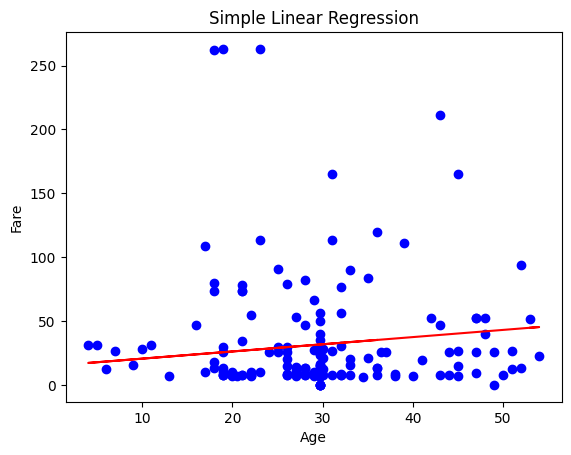

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


df = pd.read_csv("/titanic_linear_regression_cleaned.csv")


X = df[["Age"]]

y = df["Fare"]

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Create model
model = LinearRegression()

# Train model
model.fit(X_train, y_train)

# Predict
y_pred = model.predict(X_test)

# Evaluation
print("MAE :", mean_absolute_error(y_test, y_pred))
print("MSE :", mean_squared_error(y_test, y_pred))
print("R2 Score :", r2_score(y_test, y_pred))

# Regression equation
print("Slope :", model.coef_[0])
print("Intercept :", model.intercept_)


plt.scatter(X_test, y_test, color="blue")
plt.plot(X_test, y_pred, color="red")

plt.xlabel("Age")
plt.ylabel("Fare")
plt.title("Simple Linear Regression")

plt.show()

MAE : 20.538758025041215
MSE : 1115.3156140773183
R2 Score : 0.4692779813379183
Coefficients:
Age : -0.09658157473803522
Pclass : -35.23438855286984
SibSp : 1.3907410512449552
Parch : 2.9551201926005017
FamilySize : 4.345861243845466
Intercept : 111.7996416946523


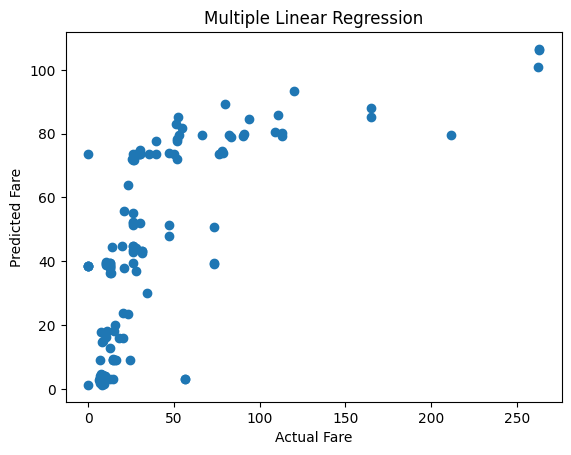

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Load dataset
df = pd.read_csv("/titanic_linear_regression_cleaned.csv")

# Independent variables
X = df[[
    "Age",
    "Pclass",
    "SibSp",
    "Parch",
    "FamilySize"
]]

# Dependent variable
y = df["Fare"]

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Create model
model = LinearRegression()

# Train model
model.fit(X_train, y_train)

# Predict
y_pred = model.predict(X_test)

# Evaluation
print("MAE :", mean_absolute_error(y_test, y_pred))
print("MSE :", mean_squared_error(y_test, y_pred))
print("R2 Score :", r2_score(y_test, y_pred))

# Coefficients
print("Coefficients:")
for feature, coef in zip(X.columns, model.coef_):
    print(feature, ":", coef)

print("Intercept :", model.intercept_)

# Plot
plt.scatter(y_test, y_pred)

plt.xlabel("Actual Fare")
plt.ylabel("Predicted Fare")
plt.title("Multiple Linear Regression")

plt.show()

In [ ]:
import heapq
def uniform_cost_search(graph, start, goal):
    pq = [(0, start, [start])]
    visited = set()#create an empty set

    while pq:# pq is not empty
        cost, node, path = heapq.heappop(pq) #pop havinng the low cost

        if node in visited: #If already visited, skip the remaining code and move to the next iteration.
            continue

        visited.add(node) #mark the current node is visited

        if node == goal: #chcek the node is reached,if reached return
            return path, cost

        for neighbor, edge_cost in graph[node]: #visit the evry neighbours of the ccurrent node
            if neighbor not in visited:
                heapq.heappush(
                    pq,
                    (cost + edge_cost, neighbor, path + [neighbor])
                )

    return None, float("inf")


graph = {
    'A': [('B', 1), ('C', 3),('D',1)],
    'B': [('E', 10)],
    'C': [('F', 8)],
    'D': [('G', 4)],
    'G':[('H',1)]
}

start = 'A'
goal = 'H'

path, cost = uniform_cost_search(graph, start, goal)

print("Shortest Path:", " -> ".join(path))
print("Total Cost:", cost)




Shortest Path: A -> D -> G -> H
Total Cost: 6


In [ ]:
import heapq

def a_star(graph, heuristic, start, goal):

    # Priority queue stores (f, g, node, path)
    pq = [(heuristic[start], 0, start, [start])]

    visited = {}

    while pq:

        # Remove node with lowest f value
        f, g, node, path = heapq.heappop(pq)

        # Goal reached
        if node == goal:
            return path, g

        # Check if a cheaper path already exists
        if node in visited and visited[node] <= g:
            continue

        visited[node] = g

        # Explore neighbors
        for neighbor, cost in graph[node]:

            new_g = g + cost

            # f(n)=g(n)+h(n)
            new_f = new_g + heuristic[neighbor]

            heapq.heappush(
                pq,
                (new_f, new_g, neighbor, path + [neighbor])
            )

    return None, float("inf")


# Graph
graph = {
    'A': [('B', 1), ('C', 4)],
    'B': [('A', 1), ('D', 2)],
    'C': [('A', 4), ('D', 1)],
    'D': [('B', 2), ('C', 1)]
}


# Heuristic values h(n)
heuristic = {
    'A': 3,
    'B': 2,
    'C': 1,
    'D': 0
}


start = 'A'
goal = 'D'

path, cost = a_star(graph, heuristic, start, goal)

print("Shortest Path:", " -> ".join(path))
print("Total Cost:", cost)


Shortest Path: A -> B -> D
Total Cost: 3


In [ ]:
import heapq

def greedy_bfs(graph, heuristic, start, goal):
    priority_queue = [(heuristic[start], start)]
    visited = set()

    while priority_queue:
        h, node = heapq.heappop(priority_queue)

        if node in visited:
            continue

        visited.add(node)
        print(node)

        if node == goal:
            return

        for neighbor in graph[node]:
            if neighbor not in visited:
                heapq.heappush(
                    priority_queue,
                    (heuristic[neighbor], neighbor)
                )


graph = {
    'A': ['B', 'C'],
    'B': ['D', 'E'],
    'C': ['F'],
    'D': [],
    'E': [],
    'F': []
}

heuristic = {
    'A': 6,
    'B': 4,
    'C': 2,
    'D': 5,
    'E': 3,
    'F': 0
}

greedy_bfs(graph, heuristic, 'A', 'F')


A
C
F
